# Анализ сроков доставки заказов Olist

## Цель анализа
Изучить своевременность доставки заказов интернет-магазина Olist, оценить частоту и величину задержек, а также подготовить данные для последующего исследования связи между сроками доставки и оценками покупателей.

## Источник данных
Brazilian E-Commerce Public Dataset by Olist (Kaggle).

## Содержание ноутбука
1. Подготовка данных и расчёт задержек доставки.
2. Анализ распределения заказов по своевременности доставки.
3. Исследование величины задержек.
4. Визуализация распределения задержек.
5. Итоги анализа.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
DATA_DIR = Path("../data/raw")
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

orders[date_columns] = orders[date_columns].apply(pd.to_datetime)

## 1. Подготовка данных и расчёт задержек доставки

Подготовим таблицу заказов для анализа сроков доставки и оставим доставленные заказы с заполненными фактической и плановой датами доставки. Затем рассчитаем разницу между этими датами в календарных днях, при этом время суток при расчёте не учитывается: получение заказа в плановую дату считается своевременной доставкой, даже если фактическое время получения отличается от планового.

In [3]:
orders_delivered = orders[
    (orders['order_status'] == 'delivered')
     & orders['order_delivered_customer_date'].notna()
     & orders['order_estimated_delivery_date'].notna()
].copy()

orders_delivered['delivery_delay_days'] = (
    orders_delivered['order_delivered_customer_date'].dt.normalize()
    - orders_delivered['order_estimated_delivery_date'].dt.normalize()
).dt.days

Проверим подготовленную таблицу и убедимся, что расчётная переменная добавлена корректно.

In [4]:
orders_delivered.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,-8
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,-6
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,-18
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,-13
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,-10


## 2. Анализ распределения заказов по своевременности доставки

Определим, какая доля заказов была доставлена раньше плановой даты, в плановую дату и позже плановой даты. Это позволит оценить распространённость задержек среди всех доставленных заказов.

In [5]:
delay_days = orders_delivered['delivery_delay_days']

delay_summary = pd.DataFrame({
    'Количество заказов': [
        (delay_days < 0).sum(),
        (delay_days == 0).sum(),
        (delay_days > 0).sum()
    ]
}, index=[
    'Раньше плановой даты',
    'В плановую дату',
    'Позже плановой даты'
])

delay_summary['Доля, %'] = (
    delay_summary['Количество заказов'] / len(orders_delivered) * 100
).round(2)

delay_summary

,Количество заказов,"Доля, %"
Раньше плановой даты,88644,91.89
В плановую дату,1292,1.34
Позже плановой даты,6534,6.77


Большинство доставленных заказов (91,89%) получены покупателями раньше плановой даты. В плановую дату доставлено 1,34% заказов, а в 6,77% случаев доставка произошла позже плановой даты. Всего выявлено 6 534 заказа с опозданием.

## 3. Исследование величины задержек

После определения доли опоздавших заказов необходимо оценить продолжительность задержек. Рассмотрим только заказы, доставленные позже плановой даты, и изучим основные статистические характеристики распределения задержек.

In [6]:
late_orders = orders_delivered[
    orders_delivered['delivery_delay_days'] > 0
].copy()

late_orders['delivery_delay_days'].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)

count    6534.000000
mean       10.620141
std        14.644955
min         1.000000
25%         3.000000
50%         7.000000
75%        13.000000
90%        22.000000
95%        31.000000
99%        71.340000
max       188.000000
Name: delivery_delay_days, dtype: float64

Среди 6 534 заказов, доставленных позже плановой даты, средняя задержка составила 10,62 дня, а медианная — 7 дней. У 75% опоздавших заказов задержка составила не более 13 дней, у 90% — не более 22 дней. При этом у 99% заказов задержка не превышала 71,34 дня.

Среднее значение выше медианы, а максимальное опоздание составило 188 дней. Это может указывать на наличие длинного правого хвоста распределения и отдельных заказов с очень большими задержками.

Экстремальные значения не исключались из анализа, поскольку имеющихся данных недостаточно, чтобы считать их ошибочными. Поэтому они учитывались при дальнейшем исследовании распределения задержек.

## 4. Визуализация распределения задержек

Для наглядного изучения характера задержек построим гистограмму. Она позволит оценить частоту различных значений и выявить особенности распределения.

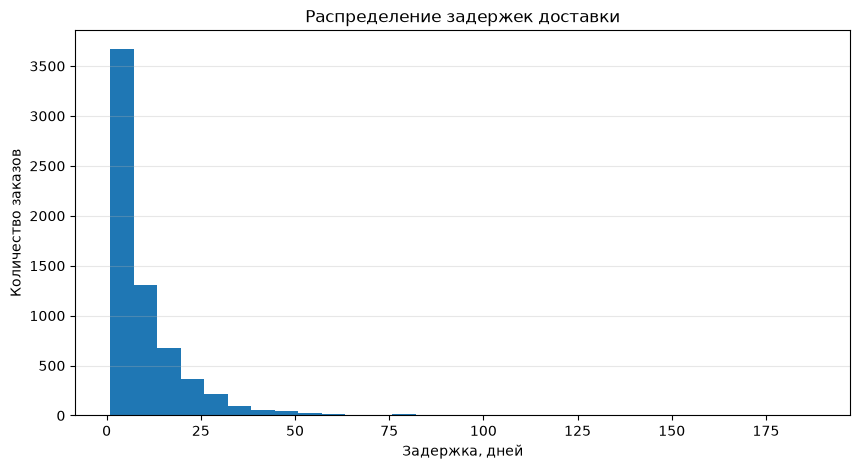

In [7]:
plt.figure(figsize=(10, 5))
plt.hist(late_orders['delivery_delay_days'], bins=30)
plt.title('Распределение задержек доставки')
plt.xlabel('Задержка, дней')
plt.ylabel('Количество заказов')
plt.grid(axis='y', alpha=0.3)
plt.show()

Для более детального изучения наиболее распространённых задержек построим дополнительную гистограмму, ограничив отображаемый диапазон 30 днями. Заказы с более длительными задержками останутся в исходной выборке, но не будут отображаться на графике.

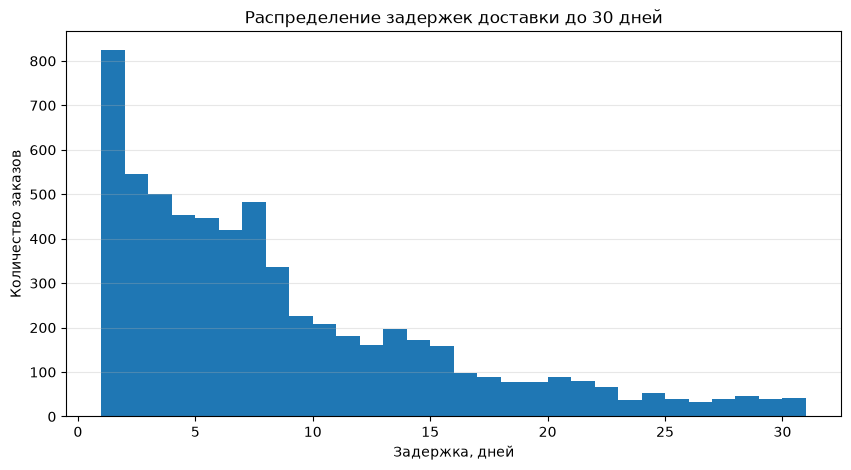

In [8]:
plt.figure(figsize=(10, 5))

plt.hist(
    late_orders['delivery_delay_days'],
    bins=30,
    range=(1, 31)
)

plt.title('Распределение задержек доставки до 30 дней')
plt.xlabel('Задержка, дней')
plt.ylabel('Количество заказов')
plt.grid(axis='y', alpha=0.3)

plt.show()

На гистограмме задержек до 30 дней наиболее высокая частота наблюдается в начале распределения, после чего высота столбцов постепенно уменьшается. Это указывает на то, что среди опоздавших заказов чаще встречаются небольшие задержки, а более длительные опоздания — реже. При этом отдельные заказы имеют значительно большие задержки, поэтому распределение характеризуется длинным правым хвостом.

## 5. Итоги анализа

В ходе анализа изучена своевременность доставки 96 470 заказов. Большинство заказов было получено раньше плановой даты (91,89%), в плановую дату доставлено 1,34%, а с опозданием — 6,77%.

Среди 6 534 опоздавших заказов средняя задержка составила 10,62 дня, медианная — 7 дней. При этом распределение имеет длинный правый хвост, а максимальная задержка составила 188 дней.

Полученные результаты показывают, что большинство заказов доставляется раньше ожидаемого срока, однако часть покупателей сталкивается с задержками различной продолжительности. В следующем исследовании будет проверено, связана ли своевременность доставки с оценками покупателей.